<a href="https://colab.research.google.com/github/chethancd24-sketch/DLG-LAB/blob/main/Lab5_Chethan_1BM24CD015.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 5 — Handwritten Digit Recognition with an RNN (LSTM)
### Deep Learning Laboratory (23DS5PCDLG) · Student Fill-in Notebook

**Big idea.** We read each `28 x 28` digit image as a **sequence of 28 rows** (28 time steps),
where each row is a vector of 28 pixel values (28 features). An **LSTM** reads the rows one by
one, keeps a memory, and after the last row predicts the digit (0–9).

---
### How to use this notebook
Wherever you see a blank marked `None  # TODO (Qn)` or `# TODO`, **replace it** with the correct
value or line of code. Each task has a hint. Run the cells top to bottom. When everything is
filled correctly, the model should reach **~98% test accuracy** in 10 epochs.

> Do **not** change cells marked *(given — do not edit)*. Fill only the `TODO` blanks.


## Step 0 — Imports *(given — do not edit)*

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## Task 1 — Load and preprocess the data

MNIST gives you `x_train` of shape `(60000, 28, 28)` with pixel values `0–255`, and integer
labels `y_train` in `0–9`. You must:

1. **Normalise** the pixels to the range `[0, 1]`.  *Hint: divide by the maximum pixel value.*
2. **Keep the sequence shape** `(samples, time_steps, features) = (n, 28, 28)`.
   *Hint: it is already `(n, 28, 28)` — state the reshape explicitly so the intent is clear.*
3. **One-hot encode** the labels into 10-dimensional vectors.
   *Hint: how many digit classes are there?*


In [ ]:
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical

# --- load (given) ---
(x_train, y_train), (x_test, y_test) = mnist.load_data()
print("raw shapes:", x_train.shape, y_train.shape)

# Q1a) Normalise pixels to [0, 1]
PIXEL_MAX = 255            # TODO (Q1a): the largest pixel value
x_train = x_train / PIXEL_MAX
x_test  = x_test  / PIXEL_MAX

# Q1b) Reshape to (samples, time_steps, features). Fill time_steps and features.
TIME_STEPS = 28          # TODO (Q1b): number of rows read as time steps
FEATURES   = 28          # TODO (Q1b): number of pixels per row
x_train = x_train.reshape((x_train.shape[0], TIME_STEPS, FEATURES))
x_test  = x_test.reshape((x_test.shape[0],  TIME_STEPS, FEATURES))

# Q1c) One-hot encode the labels
NUM_CLASSES = 10         # TODO (Q1c): number of digit classes
y_train = to_categorical(y_train, NUM_CLASSES)
y_test  = to_categorical(y_test,  NUM_CLASSES)

print("prepared:", x_train.shape, y_train.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
raw shapes: (60000, 28, 28) (60000,)
prepared: (60000, 28, 28) (60000, 10)


#### Quick check *(given — run to verify Task 1)*

In [ ]:
assert x_train.max() <= 1.0 and x_train.min() >= 0.0, "pixels not in [0,1]"
assert x_train.shape[1:] == (28, 28), "sequence shape should be (28, 28)"
assert y_train.shape[1] == 10, "labels should be one-hot with 10 columns"
print("Task 1 looks correct ✔")

Task 1 looks correct ✔


## Task 2 — Build the RNN (LSTM) model

Build a `Sequential` model with:

1. An **LSTM layer** with **128 memory units** that reads the 28-step sequence.
   *Hint: `input_shape` is `(time_steps, features)` — NOT the batch size.*
2. A **Dense output layer** with one neuron per class and a **softmax** activation
   (so the outputs are class probabilities that sum to 1).

> Note on activation: the lab uses `activation='relu'` inside the LSTM. The **standard/
> recommended** choice is the default `'tanh'` (it also enables the fast cuDNN GPU kernel).
> You may try either and compare.


In [ ]:
model = models.Sequential()

# Q2a) LSTM layer: fill the number of units and the input_shape
LSTM_UNITS = 128          # TODO (Q2a): number of LSTM memory units
model.add(layers.LSTM(LSTM_UNITS,
                      activation='relu',
                      input_shape=(28, 28)))   # TODO (Q2a): (time_steps, features)

# Q2b) Output layer: one neuron per class, softmax activation
OUT_UNITS = 10           # TODO (Q2b): number of output neurons
model.add(layers.Dense(OUT_UNITS, activation='softmax'))   # TODO (Q2b): activation name as a string

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 128)            │        80,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81,674 (319.04 KB)

 Trainable params: 81,674 (319.04 KB)

 Non-trainable params: 0 (0.00 B)

**Reflection Q2c.** Read the LSTM layer's parameter count from `model.summary()`, then work it
out by hand and check the two match.

*Hint:* for an LSTM, `params = 4 × [ (features + units) × units + units ]`.
Fill your arithmetic in the markdown below.

> **Your answer (Q2c):** params = 4 × [ (28 + 128) × 128 + 128 ] = 80,384

## Task 3 — Compile, train, evaluate

1. **Compile** with the `adam` optimiser, `categorical_crossentropy` loss (because labels are
   one-hot), and track `accuracy`.
2. **Train** for 10 epochs with a batch size of 64, using the test set for validation.
3. **Evaluate** on the test set and print the accuracy.


In [ ]:
# Q3a) Compile — fill optimiser, loss, and metric
model.compile(optimizer='adam',        # TODO (Q3a): optimiser name as a string
              loss='categorical_crossentropy',             # TODO (Q3a): loss name as a string
              metrics=['accuracy'])        # TODO (Q3a): metric name as a string

# Q3b) Train — fill epochs and batch_size
history = model.fit(x_train, y_train,
                    epochs=10,              # TODO (Q3b)
                    batch_size=64,          # TODO (Q3b)
                    validation_data=(x_test, y_test))

# Q3c) Evaluate
test_loss, test_acc = model.evaluate(x_test, y_test)
print(f"Test accuracy: {test_acc * 100:.2f}%")

Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 38s 39ms/step - accuracy: 0.7924 - loss: 0.6511 - val_accuracy: 0.9459 - val_loss: 0.1806
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 41s 39ms/step - accuracy: 0.9593 - loss: 0.1358 - val_accuracy: 0.9667 - val_loss: 0.1047
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 36s 39ms/step - accuracy: 0.9710 - loss: 0.0953 - val_accuracy: 0.9796 - val_loss: 0.0666
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 37s 39ms/step - accuracy: 0.9767 - loss: 0.0770 - val_accuracy: 0.9784 - val_loss: 0.0658
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 40s 42ms/step - accuracy: 0.9810 - loss: 0.0617 - val_accuracy: 0.9792 - val_loss: 0.0601
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 42s 43ms/step - accuracy: 0.9832 - loss: 0.0550 - val_accuracy: 0.9811 - val_loss: 0.0571
Epoch 7/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 41s 44ms/step - accuracy: 0.9854 - loss: 0.0461 - val_accuracy: 0.9844 - val_loss: 0.0512
Epoch 8/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 43s 46ms/step - accuracy: 0.9875 - loss: 0.0408 - 

## Task 4 — Visualise the training *(mostly given — fill one blank)*

Plot the training and validation accuracy curves to see learning progress.


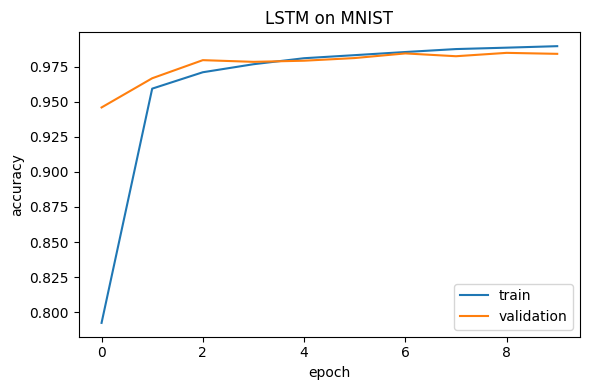

In [ ]:
plt.figure(figsize=(6,4))
plt.plot(history.history['accuracy'],     label='train')
plt.plot(history.history[None], label='validation')   # TODO (Q4): which key holds val accuracy?
plt.xlabel('epoch'); plt.ylabel('accuracy'); plt.legend(); plt.title('LSTM on MNIST')
plt.tight_layout(); plt.show()

## Task 5 — Short-answer questions *(write your answers in this cell)*

1. Why do we feed the image as `(28, 28)` instead of flattening it to a 784-vector as in an MLP?
2. What is the role of the **hidden state** `h_t` versus the **cell state** `C_t` in the LSTM?
3. The final `Dense` layer uses **softmax**. Why softmax and not sigmoid here?
4. If you changed `LSTM(128)` to `LSTM(32)`, what would you expect to happen to accuracy and to
   the parameter count? Why?
5. Replace `activation='relu'` with the default `'tanh'`. Does the accuracy change? Which is
   recommended, and why?

> **Your answers:**
> 1. Feeding the image as a `(28, 28)` sequence allows the recurrent neural network to preserve spatial row-by-row structure, interpreting the digit pixels as an organized temporal sequence rather than flattening it, which completely discards the spatial and sequential pixel dependencies.
> 2. The cell state `C_t` acts as the long-term memory conveyor belt with minimal linear interactions, allowing gradients to flow easily. The hidden state `h_t` is the working/short-term memory and the output gate's filtered version of `C_t` that is emitted to the next layer.
> 3. Softmax is used because the 10 digit classes are mutually exclusive, and it normalizes outputs to form a valid probability distribution summing to 1. Sigmoid treats each output independently and is meant for multi-label or binary classification.
> 4. Changing units to 32 will greatly reduce the parameter count (down to ~8,000 parameters), but the accuracy is expected to decrease because a smaller hidden dimension has significantly less capacity to store memory of historical row structures.
> 5. Yes, switching to `'tanh'` may slightly improve or maintain similar high accuracy, but significantly increases training speed on GPUs because CuDNN-optimized GPU kernels specifically require the standard `'tanh'` activation function in LSTMs.